# EDA реальных данных кейса М.Видео: поля, пропуски, распределения, поисковый спрос

Артефакт №3 комплекта сдачи — «EDA: разбор полей, пропусков, распределений». Посчитан на **полной выгрузке
организаторов**, а не на сэмпле: 1 177 200 карточек (`sku_desc`), YML-каталог М.Видео
(546 069 офферов, 20 975 731 строк характеристик, 6 963 категорий) и
30 991 350 поисковых кликов (`query_clicks`). Краткая версия с графиками — [docs/EDA.md](../docs/EDA.md).

**Как воспроизвести** (ноутбук ≈ 1,5 мин и ≤ 4 ГБ RAM; `skus.pkl` здесь не читается — только `data/processed/*.parquet`):

```bash
uv pip install -p .venv/bin/python -e ".[dev,eda]"          # + matplotlib и Jupyter
bash scripts/download_data.sh && .venv/bin/attrx prepare   # data/raw -> data/processed, один раз (≈ 8 мин)
.venv/bin/attrx traffic                                     # трафик-веса атрибутов из поисковых кликов (≈ 5 мин)
.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb
.venv/bin/attrx eda-real                                    # то же без Jupyter: графики + JSON с цифрами
```

Расчёты — в `src/attrx/data/eda.py` (агрегаты DuckDB поверх parquet), трафик-веса — в `src/attrx/data/traffic.py`.
Графики сохраняются в `docs/img/eda_*.png`, цифры — в `data/processed/eda_stats.json` и `data/processed/business_stats.json`.

### Главное
1. Эталон (оффер YML с атрибутами) есть у **20,5%** карточек (241 355),
   но на эти товары приходится **93,2%** поисковых кликов. У **74,8%**
   карточек нет ни оффера, ни категории — только текст.
2. «Пропуски» содержательные, а не NULL: 30% описаний короче 200 символов, HTML в эталонных 72–81%
   исходных описаний, 33% карточек без оффера — заголовки-заглушки «Чехол … GSS -».
3. Длинный хвост: 3 595 листовых категорий, медиана 10 офферов, у 1 772
   меньше 10; хвост из 3 366 категорий даёт 23% кликов поиска.
4. 10 696 разных характеристик; у 23% пар «SKU × свойство» есть и бакет фильтра («1 ТБ»),
   и точное значение («1024 ГБ»). Одна единица памяти пишется 12 способами.
5. Потолок recall: значение есть в тексте у 98–99% брендов и памяти смартфонов, но лишь у 34%
   диагоналей смартфонов и 12% цветов iPhone.
6. В **56,5%** поисковых кликов запрос называет атрибут, в 24,9% — характеристику кроме бренда
   и модели (телевизоры — диагональ 50%, наушники — тип подключения 39%).
7. Справедливость: у офферов маркетплейса все ключевые свойства заполнены в 82%
   случаев против 95% у М.Видео, хотя тексты у них не беднее.

In [1]:
import json

import pandas as pd
from IPython.display import display

from attrx.config import ROOT
from attrx.data import eda
from attrx.data.eda import num, pct

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
eda.setup_style()
e = eda.EDA(processed=ROOT / "data" / "processed", raw=ROOT / "data" / "raw", img=ROOT / "docs" / "img")


def as_pct(df, cols, digits=1):
    """Копия таблицы с долями в процентах — для чтения глазами."""
    out = df.copy()
    for c in cols:
        out[c] = out[c].map(lambda v: "—" if pd.isna(v) else pct(v, digits))
    return out

## 1. Источники и как они связываются

Три файла организаторов связываются по `sku_id`: описания карточек (`sku_desc` → `cards`), YML-фид каталога
(`skus.pkl` → `offers`, `params`, `categories`) и поисковые клики (`query_clicks`). Оффер YML — это и есть размеченная
часть: `vendor`, `model` и `param[]` заведены контент-командой М.Видео, поэтому они служат эталоном (gold),
а входом модели остаётся только текст карточки.

,источник,строк,ключ,что внутри
0,sku_desc.parquet → cards,1177200,sku_id,"заголовок + описание (HTML → текст, блок «Характеристики» → seller_attrs)"
1,skus.pkl (YML) → offers,546069,sku_id = @id,"vendor, model, name, категория, продавец — эталон"
2,skus.pkl (YML) → params,20975731,sku_id,"10 696 имён параметров, 15% служебных"
3,skus.pkl (YML) → categories,6963,id,"дерево 3 уровня, 5 788 листьев, 3 595 с офферами"
4,query_clicks.parquet,30991350,sku_id,"клики поиска: 332 753 SKU, 1 397 077 уникальных запросов"


,связка,SKU,доля,от чего доля
0,карточки ∩ офферы (= есть эталон),241355,"20,5%",доля карточек
1,офферы ∩ карточки,241355,"44,2%",доля офферов
2,"карточки без оффера, категория по seo_id кликов",55213,"4,7%",доля карточек
3,карточки без оффера и без кликов (только текст),880632,"74,8%",доля карточек
4,кликнутые SKU ∩ офферы,241661,"93,2%",доля кликов
5,кликнутые SKU ∩ карточки,158158,"63,8%",доля кликов


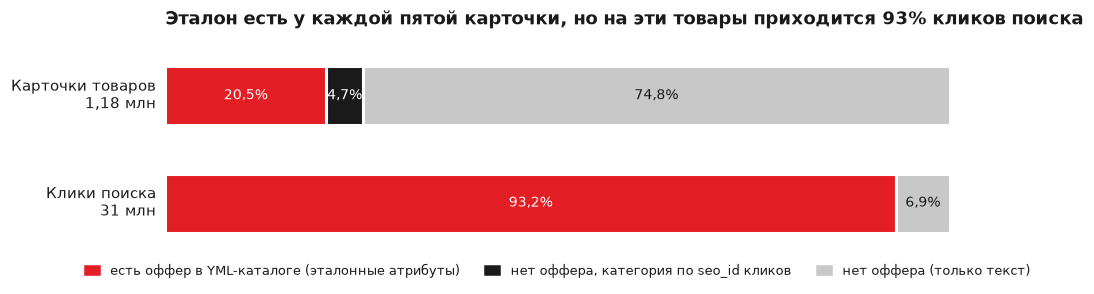

In [2]:
src, joins = eda.sources(e)
display(src)
display(as_pct(joins, ["доля"]))
eda.fig_coverage(e);

**Выводы.**
- Эталон есть у 241 355 карточек (20,5%); это 44,2% офферов каталога —
  остальные офферы в выгрузку описаний не попали. Метрики качества честно считаются только на этой части
  (holdout — 24 143 карточки с эталоном, сплит `md5(sku_id)`).
- Ещё у 55 213 карточек (4,7%) нет оффера, но есть категория по `seo_id` кликов
  (совпадает с категорией каталога у 97,7% SKU). **880 632 карточек (74,8%) — только текст**: ни категории,
  ни атрибутов → пайплайну нужен классификатор категории по тексту и извлечение без опоры на каталог (cold start).
- Эталонная часть — это «голова» спроса: 93,2% кликов поиска приходятся на SKU с оффером. Значит, на эталоне
  мы меряем качество там, где оно приносит деньги, а на карточках без оффера — показываем покрытие.

## 2. Поля, типы, пропуски

Сначала формальная заполненность полей, затем содержательные пропуски: пустые и короткие тексты, шаблонные
заголовки, HTML-разметка, блок «Характеристики» от продавца — отдельно для карточек М.Видео, партнёров маркетплейса
и карточек без оффера. Доля HTML считается по исходным описаниям `data/raw/sku_desc.parquet` на выборке 20%
(`sku_id % 5 = 0`).

In [3]:
fields = eda.fields(e)
display(as_pct(fields, ["заполнено", "пусто ('' или {})"], 2))

,таблица,поле,тип,заполнено,пусто ('' или {})
0,cards,sku_id,VARCHAR,"100,00%","0,00%"
1,cards,title,VARCHAR,"100,00%","0,00%"
2,cards,description_clean,VARCHAR,"100,00%","0,01%"
3,cards,seller_attrs,VARCHAR,"100,00%","68,88%"
4,cards,n_seller_attrs,INTEGER,"100,00%","0,00%"
5,cards,category_id,VARCHAR,"25,19%","0,00%"
6,cards,category_source,VARCHAR,"25,19%","0,00%"
7,cards,seller,VARCHAR,"20,50%","0,00%"
8,cards,seller_type,VARCHAR,"20,50%","0,00%"
9,cards,has_offer,BOOLEAN,"100,00%","0,00%"


segment,М.Видео,маркетплейс,без оффера
карточек,56 342,185 013,935 845
заголовок < 15 симв.,"0,0%","0,0%","4,2%"
заголовок-заглушка «… GSS -»,"0,0%","0,0%","32,8%"
пустое описание,"0,0%","0,0%","0,0%"
описание < 50,"0,7%","0,1%","9,1%"
описание < 200,"3,0%","1,0%","37,3%"
блок «Характеристики»,"2,1%","8,0%","37,4%"
пар в блоке (среднее),6.4,9.7,6.8
нет категории,"0,0%","0,0%","94,1%"
HTML в исходнике,"80,5%","72,1%","43,1%"


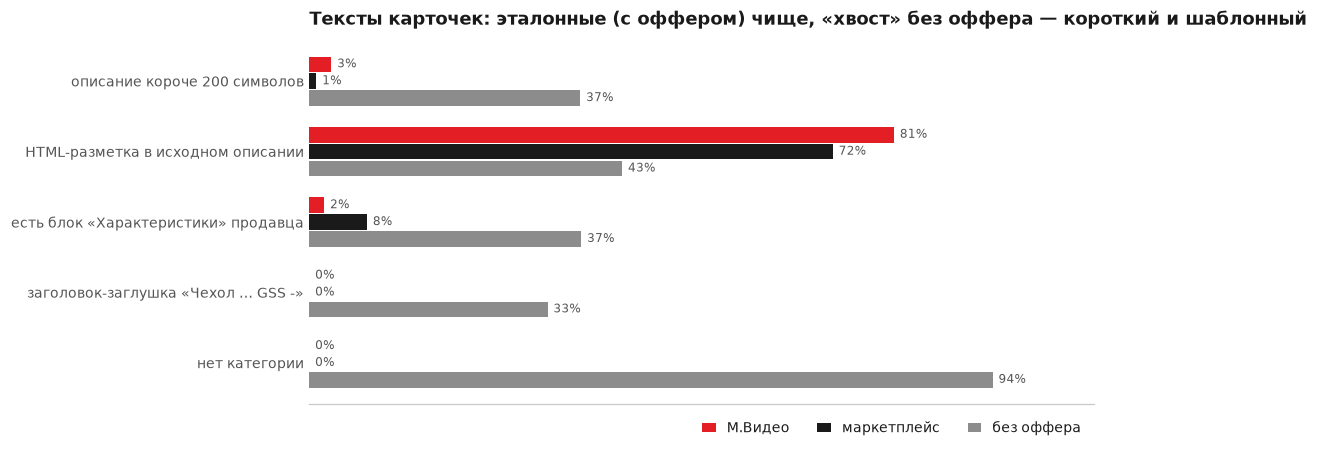

In [4]:
q = eda.quality(e)
cols = ["short_title", "placeholder_title", "empty_desc", "desc_lt_50", "desc_lt_200", "html", "entities", "char_block",
        "no_category"]
show = as_pct(q, cols)
show["cards"] = q["cards"].map(num)
show["seller_attrs_if_block"] = q["seller_attrs_if_block"].round(1)
display(show.rename(columns={
    "cards": "карточек", "short_title": "заголовок < 15 симв.", "placeholder_title": "заголовок-заглушка «… GSS -»",
    "empty_desc": "пустое описание", "desc_lt_50": "описание < 50", "desc_lt_200": "описание < 200",
    "html": "HTML в исходнике", "entities": "HTML-сущности (&nbsp;)", "char_block": "блок «Характеристики»",
    "seller_attrs_if_block": "пар в блоке (среднее)", "no_category": "нет категории"}).T)
eda.fig_quality(e, q);

Как это выглядит в данных — заглушки, HTML и блок «Характеристики» до и после очистки (`attrx.data.text`):

In [5]:
con = e.con
placeholders = con.execute(f"""SELECT title, left(description_clean, 70) AS description, seller_attrs FROM {e.p('cards')}
    WHERE regexp_matches(title, ' (UNIMALL|GSS) -$') USING SAMPLE 3 ROWS (reservoir, 7)""").df()
display(placeholders)
raw = con.execute(f"""SELECT r.sku_id, r.description FROM read_parquet('{e.raw / "sku_desc.parquet"}') r
    WHERE r.sku_id % 997 = 3 AND r.description LIKE '%<br%' AND r.description LIKE '%Характеристики%' LIMIT 1""").fetchone()
clean = con.execute(f"SELECT description_clean, seller_attrs FROM {e.p('cards')} WHERE sku_id = '{raw[0]}'").fetchone()
print("ИСХОДНИК:", raw[1][:420].replace("\n", " "), "...\n")
print("ПОСЛЕ ОЧИСТКИ:", clean[0][:300], "...\n")
print("SELLER_ATTRS:", json.dumps(json.loads(clean[1]), ensure_ascii=False)[:300])

,title,description,seller_attrs
0,"Защитное стекло для смартфона, телефона GSS -",Гидрогелевая пленка для смартфонов.\n\nЛучшие товары из Китая,"{""Назначение"": ""смартфоны и мобильные телефоны"", ""Совместимость"": ""Vivo X90 Pro"", ""Диа..."


ИСХОДНИК: Матрас Piterson Dana — это надежная модель с независимым пружинным блоком, обеспечивающая правильную поддержку позвоночника во время сна. Благодаря зональной системе распределения нагрузки, матрас подстраивается под анатомию тела, снимая мышечное напряжение и обеспечивая комфортный отдых.<br><br>В качестве наполнителя используются высокоэластичная пена (ППУ) и плотный слой войлока, которые продлевают срок службы изде ...

ПОСЛЕ ОЧИСТКИ: Матрас Piterson Dana — это надежная модель с независимым пружинным блоком, обеспечивающая правильную поддержку позвоночника во время сна. Благодаря зональной системе распределения нагрузки, матрас подстраивается под анатомию тела, снимая мышечное напряжение и обеспечивая комфортный отдых.

В качеств ...

SELLER_ATTRS: {"Тип": "На независимых пружинах", "Нагрузка на спальное место": "до 100 кг", "Высота": "17 см", "Жесткость": "Мягкий"}


**Выводы.**
- Формальных NULL почти нет: заголовок и описание есть у всех карточек (пустых описаний 0,01%),
  `vendor` пуст у 11 офферов. Категория заполнена лишь у 25,2% карточек, продавец — у
  20,5% (только у карточек с оффером).
- Настоящие пропуски — содержательные: 30% описаний короче 200 символов (без оффера — 37%, у эталонных
  1–3%), 33% карточек без оффера — заголовки-заглушки
  «Тип товара GSS -» / «UNIMALL -» без бренда и модели (два продавца вне каталога).
- HTML-разметка есть в 43–81% исходных описаний → очистка обязательна (`clean_html`, двойное экранирование,
  списки `<li>` → «•»).
- Блок «Характеристики» продавца разобран у 31% карточек, но почти весь — вне каталога: 37% у карточек
  без оффера против 2–8% у эталонных. Для «хвоста» это самый дешёвый источник атрибутов
  (пары «ключ: значение» → алиасы таксономии), на эталоне же главный источник — свободный текст.

## 3. Длины текстов

,заголовок p10,заголовок медиана,заголовок p90,описание p10,описание p25,описание медиана,описание p75,описание p90
segment,,,,,,,,
М.Видео,31.0,49.0,77.0,329.0,586.0,868.0,1351.0,1774.0
маркетплейс,31.0,58.0,99.0,517.0,653.0,1057.0,1294.0,1636.8
без оффера,17.0,39.0,71.0,51.0,76.0,440.0,932.0,1265.0


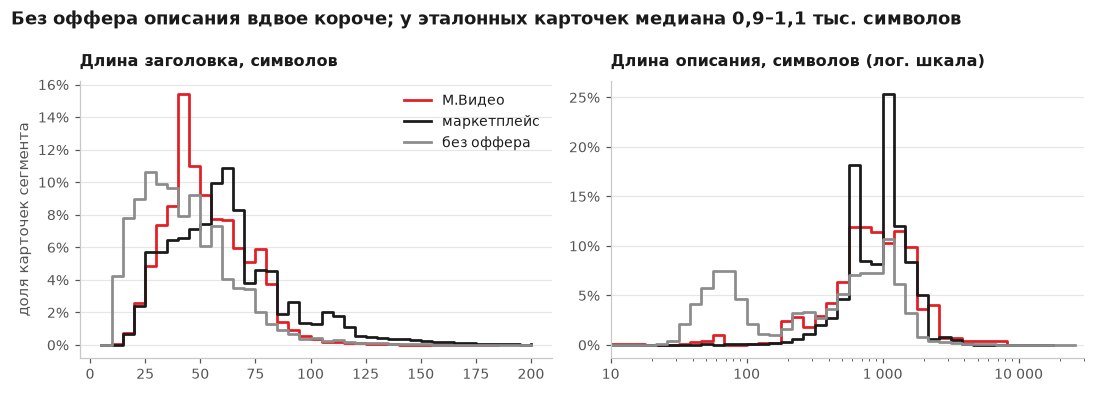

In [6]:
display(eda.lengths(e))
eda.fig_lengths(e);

**Выводы.**
- Медиана заголовка: М.Видео 49, маркетплейс 58, без оффера 39 символов.
  Медиана описания: 868 / 1 057 / 440 символов; у карточек без оффера второй пик
  на 50–100 символах — шаблонные описания заглушек.
- Тексты длинные (p90 ≈ 1 637–1 774 символов, ~500 токенов) — гнать LLM по каждой из 1,18 млн карточек дорого.
  Отсюда гибрид: правила и NER на всех карточках, LLM — только для того, что дешёвые методы не нашли.
- У коротких текстов низкий потолок полноты: чего нет в тексте, то нельзя честно извлечь (см. раздел 6).

## 4. Категории: длинный хвост и глубина дерева

Полосы head / torso / tail — по накопленной доле офферов: head — категории, дающие первые 50% офферов,
torso — до 80%, tail — остальное.

,полоса,категорий,офферов,кликов,карточек с эталоном,медиана офферов,доля офферов,доля кликов,доля карточек с эталоном
0,head,29,272417,7735128,109927,5338.0,"49,9%","25,0%","45,5%"
1,torso,200,164268,16069478,75222,631.0,"30,1%","51,9%","31,2%"
2,tail,3366,109345,7167288,56184,8.0,"20,0%","23,1%","23,3%"


,уровень,категорий,листьев,офферов
0,0,96,0,0.0
1,1,1088,9,0.0
2,2,5779,5779,546030.0


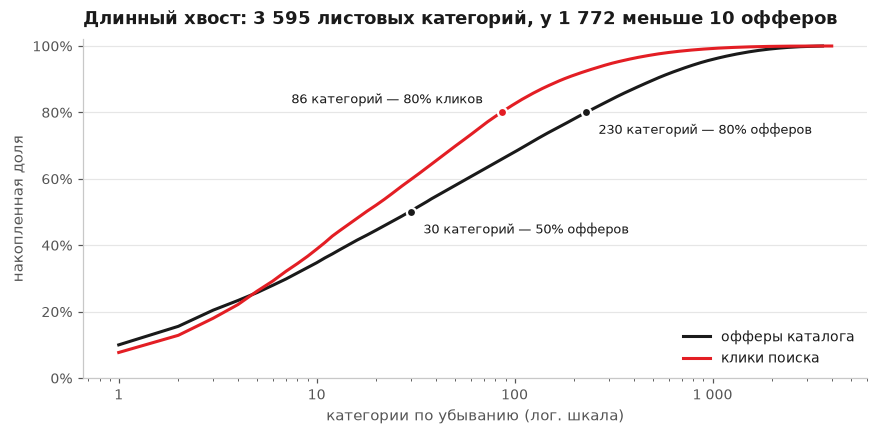

In [7]:
bands, depth = eda.categories(e)
display(as_pct(bands, ["offers_share", "clicks_share", "gold_cards_share"]).rename(columns={
    "band": "полоса", "categories": "категорий", "offers": "офферов", "clicks": "кликов", "gold_cards": "карточек с эталоном",
    "median_offers": "медиана офферов", "offers_share": "доля офферов", "clicks_share": "доля кликов",
    "gold_cards_share": "доля карточек с эталоном"}))
display(depth.rename(columns={"depth": "уровень", "categories": "категорий", "leaves": "листьев", "offers": "офферов"}))
eda.fig_long_tail(e);

**Выводы.**
- Дерево каталога — 3 уровня: 96 корней → 1 088 разделов → 5 779 категорий нижнего уровня; все офферы
  лежат в листьях третьего уровня, офферы есть у 3 595 из 5 788 листьев.
- Хвост очень длинный: медиана 10 офферов на категорию, у 1 772 категорий (49%) меньше 10 офферов,
  30 категорий дают 50% офферов, 230 — 80%. Спрос сконцентрирован сильнее: 18 категорий — 50% кликов,
  86 — 80%.
- Но хвост нельзя бросить: 3 366 категорий tail (медиана 8 офферов) — это 23% кликов поиска и
  23% карточек с эталоном. Ручные правила на каждую категорию не масштабируются → таксономия и словари строятся из
  данных (`param_stats.parquet` — заполненность всех параметров во всех категориях), для хвоста — универсальные атрибуты
  + LLM; метрики отчитываем по полосам head/torso/tail.

## 5. Структурированные атрибуты каталога

### 5.1 Сколько характеристик у оффера и как они устроены

In [8]:
po = eda.params_overview(e)
display(as_pct(po, ["< 5 характеристик", "≥ 20 характеристик"]))
p = e.stats["params"]
print(f"пар (SKU, свойство): {num(p['sku_param_pairs'])}; бакет + точное: {pct(p['pairs_bucket_and_exact'], 1)}, "
      f"только точное (_search): {pct(p['pairs_exact_only'], 1)}, только бакет: {pct(p['pairs_bucket_only'], 1)}; "
      f"медиана имён параметров на категорию: {p['median_param_names_per_category']:.0f}")
example = con.execute(f"""SELECT p.name, p.is_search, p.unit, p.value FROM {e.p('params')} p
    JOIN {e.p('offers')} o USING (sku_id) WHERE o.category_id = '761'
    AND p.name IN ('Встроенная память', 'Диагональ', 'Диагональ экрана', 'Емкость аккумулятора', 'Цвет', 'Продавец', 'Подборки')
    AND p.sku_id = (SELECT min(sku_id) FROM {e.p('offers')} WHERE category_id = '761' AND n_params > 40)""").df()
display(example)

,офферов,медиана характеристик,p10,p90,< 5 характеристик,≥ 20 характеристик
segment,,,,,,
М.Видео,84861,17.0,1.0,70.0,"20,5%","42,4%"
маркетплейс,461208,19.0,1.0,47.0,"15,3%","49,2%"


пар (SKU, свойство): 14 398 922; бакет + точное: 23,3%, только точное (_search): 71,3%, только бакет: 5,4%; медиана имён параметров на категорию: 16


,name,is_search,unit,value
0,Подборки,False,NaN,в Уфе
1,Подборки,False,NaN,в Новосибирске
2,Подборки,False,NaN,с мини сим картой
3,Подборки,False,NaN,китайские
4,Емкость аккумулятора,True,мАч,2000
5,Диагональ,True,"""",5
6,Цвет,True,NaN,черный
7,Диагональ экрана,False,NaN,"5"""
8,Встроенная память,False,NaN,до 8 ГБ
9,Цвет,False,NaN,черный


### 5.2 Заполненность ключевых свойств в топ-категориях по кликам

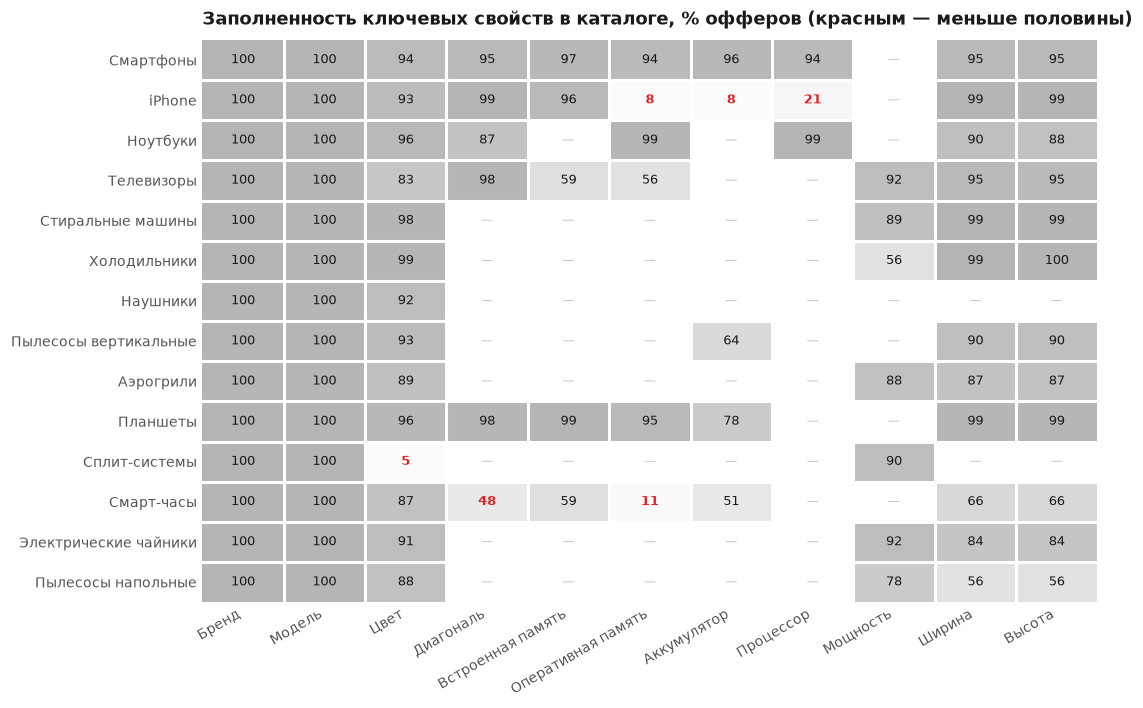

In [9]:
fm = eda.fill_matrix(e)
eda.fig_fill(e, fm);

### 5.3 Распределения значений ключевых атрибутов

Смартфоны: встроенная память: 256 ГБ — 44%, 512 ГБ — 24%, 128 ГБ — 18%, 1 ТБ — 7%, 64 ГБ — 1%, 2 ТБ — 1%
Смартфоны: цвет (фильтр): черный — 23%, другие цвета — 15%, белый — 9%, синий — 9%, голубой — 8%, зеленый — 7%, серый — 6%, серебристый — 6%
Смартфоны: ёмкость аккумулятора, мАч: 5000 — 36%, 6000 — 7%, 4900 — 6%, 6500 — 5%, 5500 — 4%, 4000 — 4%, 7000 — 4%
Ноутбуки: оперативная память, ГБ: 16 — 61%, 8 — 16%, 32 — 10%, 24 — 6%, 10 — 2%, 48 — 1%
Ноутбуки: диагональ: 15.6"(39.6 см) — 20%, 16"(40.6 см) — 16%, 14"(35.5 см) — 11%, 13.6" — 9%, 15.3"(38.8 см) — 7%, 14.2"(36.1 см) — 6%, 17.3"(43.9 см) — 5%
Телевизоры: диагональ, дюймы: 32 — 17%, 43 — 16%, 55 — 15%, 65 — 11%, 50 — 11%, 24 — 7%, 40 — 6%, 75 — 5%
Смартфоны: бренд: Apple — 38%, Samsung — 26%, Xiaomi — 12%, realme — 3%, HONOR — 3%, HUAWEI — 3%, Tecno — 3%, POCO — 2%


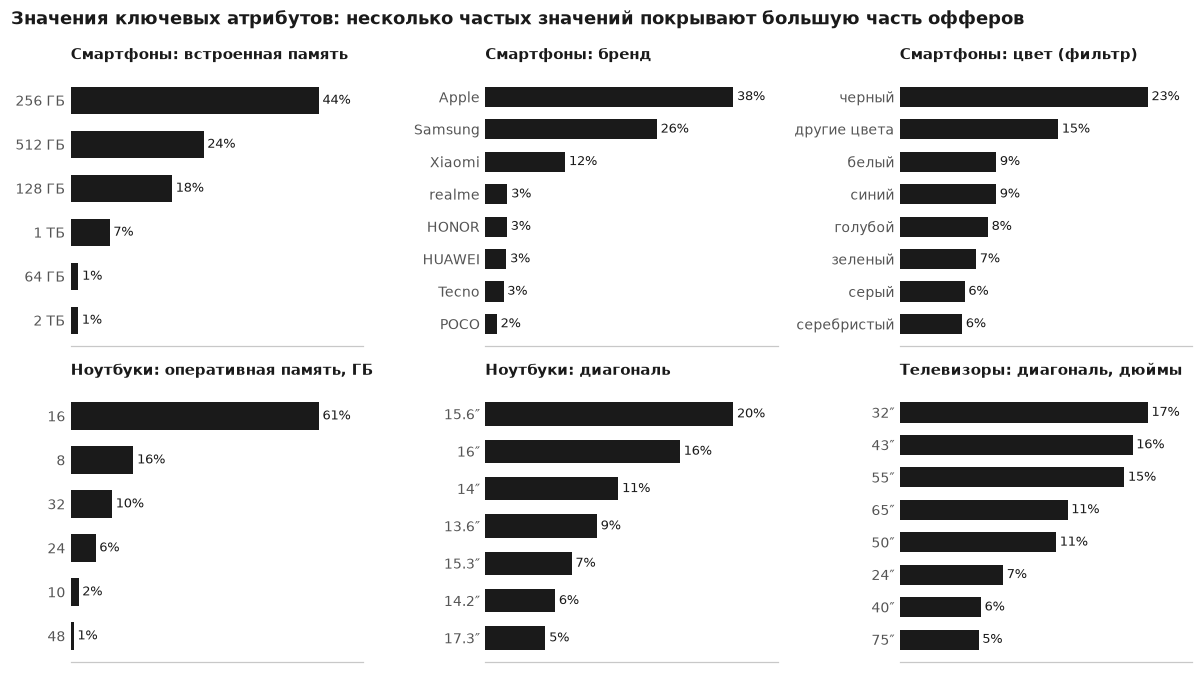

In [10]:
vals = eda.values(e)
for name, df in vals.items():
    print(f"{name}: " + ", ".join(f"{v} — {pct(s)}" for v, s in zip(df.value, df.share, strict=True)))
eda.fig_values(e, vals);

### 5.4 Почему нужна нормализация: реальные примеры

,0,1,2,3,4,5,6,7,8,9,10,11
написание,GB,G,Gb,TB,ГБ,Гб,ТБ,Tb,Г,Тб,gb,гб
упоминаний в заголовках,42401,11974,9060,5726,2789,1322,739,642,165,130,116,22


,"формат RAM/ROM в заголовке (смартфоны, планшеты)",доля заголовков
0,«8/256GB»,"52,1%"
1,«12+256»,"3,8%"
2,"«8GB/256GB», «8GB+256GB»","1,5%"


,категория,заголовков,"«55""»",«55 дюймов»,«139 см»,"код модели с диагональю («55C6K», «UE55DU7100»)"
0,Ноутбуки,2674,"45,4%","0,0%","0,0%",—
1,Телевизоры,2829,"1,6%","0,4%","0,1%","75,0%"
2,Смартфоны,5543,"0,0%","0,0%","0,0%",—


,цвет в заголовке смартфона,доля
0,"английское название цвета (Black, Titanium Gray, Starlight)","51,2%"
1,русское название цвета,"34,6%"


,цвет производителя,цвет в фильтре,офферов
0,Black,черный,661
1,White,белый,309
2,Silver,серебристый,194
3,космический оранжевый,оранжевый,191
4,Blue,синий,189
5,серебро,серебристый,185
6,Cosmic Orange,оранжевый,177
7,Pink,розовый,119
8,Green,зеленый,114
9,Deep Blue,синий,102


,категория,параметр-бакет (фильтр),значение,точный параметр,значение
0,Смартфоны,Встроенная память,1 ТБ,Встроенная память (ROM),1024 ГБ
1,Смартфоны,Диагональ экрана,"6.6"" и более",Диагональ,"6.7 """
2,Телевизоры,Диагональ,50,Диагональ экрана,127 см
3,Холодильники,Высота холодильника,200 см и более,Высота,200 см
4,Посудомоечные машины,Ширина,56 - 60 см,Ширина,598 мм
5,Стиральные машины,Макс загрузка (хлопок),8 - 8.9 кг,Максимальная загрузка,8 кг


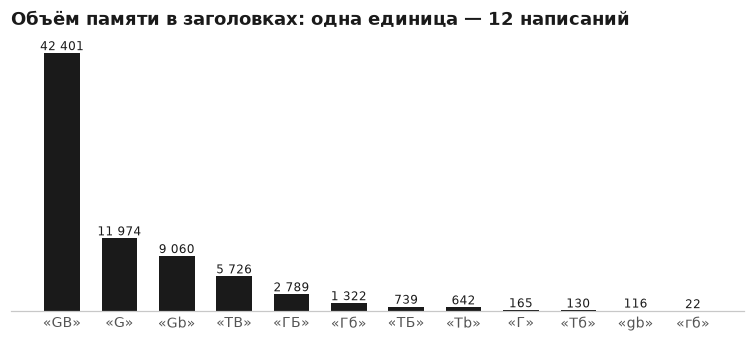

In [11]:
nt = eda.normalization(e)
display(nt["units"].T)
display(as_pct(nt["pairs"], ["доля заголовков"]))
display(as_pct(nt["diagonal"], ["«55\"»", "«55 дюймов»", "«139 см»", "код модели с диагональю («55C6K», «UE55DU7100»)"]))
display(as_pct(nt["colors"], ["доля"]))
display(nt["color_synonyms"])
display(nt["buckets"])
eda.fig_units(e, nt);

**Выводы.**
- В каталоге 20 975 731 строк характеристик и 10 696 разных имён; 15% строк — служебные (продавец,
  подборки, бонусы, гарантия) и в эталон не идут. Медиана — 19 характеристик на оффер
  (у М.Видео 17); у 15–20% офферов их меньше пяти.
- Одно свойство часто хранится дважды: бакет фильтра и точное `_search`-значение (у 23% пар). Бакет
  «1 ТБ» ↔ точное «1024 ГБ», «6.6" и более» ↔ 6.7", у телевизоров «Диагональ» 50 ↔ «Диагональ экрана» 127 см, у посудомоек
  «56 - 60 см» ↔ 598 мм. Эталоном берём точное значение, бакет выводится из него.
- Бренд и модель заполнены у 100% офферов, цвет — у 83–99% в топ-категориях, но есть системные дыры:
  у iPhone RAM и ёмкость аккумулятора — 8%, процессор — 21% (Apple их не публикует); у смарт-часов диагональ — 48%,
  у сплит-систем цвет — 5%.
- Значения сконцентрированы: 256/512/128 ГБ — 86% смартфонов, 16 ГБ — 61% ноутбуков,
  пять диагоналей — 70% телевизоров → справочники допустимых значений компактны.
- Нормализация обязательна: 12 написаний единицы памяти (GB 42 401, G 11 974, Gb 9 060, … гб 22),
  RAM/ROM парой «8/256GB» в 52% заголовков смартфонов и планшетов и «12+256» ещё в 4%; цвет смартфона в заголовке
  по-английски в 51% случаев (Black, Titanium Gray, Starlight), а в фильтре — по-русски («Cosmic Orange» → «оранжевый»,
  «Blue» → и «синий», и «голубой»); диагональ телевизора явно написана лишь в 2% заголовков,
  но в 75% закодирована в коде модели (55C6K, UE55DU7100).

## 6. Извлекаемость: есть ли эталонное значение в тексте карточки

Для каждого атрибута — доля офферов, у которых значение из каталога буквально или в нормализованной форме
(`256 ГБ ~ 256GB`, `1024 ГБ ~ 1 ТБ`) встречается в title + описании + seller_attrs. Это **потолок recall** для любого
метода без галлюцинаций. Посчитано в `attrx prepare` (`taxonomy_candidates.json`, до 1 500 офферов на категорию).

,категория,атрибут,параметр,fill,в тексте,в тексте (с голым числом),в заголовке,проверено офферов
0,Смартфоны,бренд,vendor,"100,0%","99,0%","99,0%","99,0%",1500
1,Смартфоны,модель,model,"100,0%","97,9%","97,9%","97,9%",1500
2,Смартфоны,память,Встроенная память (ROM),"96,6%","99,2%","99,7%","95,6%",1500
3,Смартфоны,RAM,Оперативная память (RAM),"94,4%","41,3%","97,0%","1,3%",1497
4,Смартфоны,цвет,Цвет,"93,7%","42,0%","42,0%","37,3%",1472
5,Смартфоны,аккумулятор,Емкость аккумулятора,"96,2%","49,8%","49,8%","0,0%",1498
6,Смартфоны,диагональ,Диагональ,"95,5%","33,5%","50,8%","0,0%",1479
7,iPhone,цвет,Цвет,"92,8%","11,8%","11,8%","10,0%",1080
8,Ноутбуки,процессор,Модель процессора,"98,3%","90,6%","90,9%","65,1%",1319
9,Ноутбуки,RAM,Оперативная память (RAM),"98,7%","81,9%","97,2%","39,5%",1322


все заметные свойства топ-25 категорий (fill ≥ 50%): 1575; в тексте хотя бы у половины карточек — 109 (6,9%); флаги «Да/Нет» — 43%; медиана извлекаемости — 1% (без флагов — 9%)


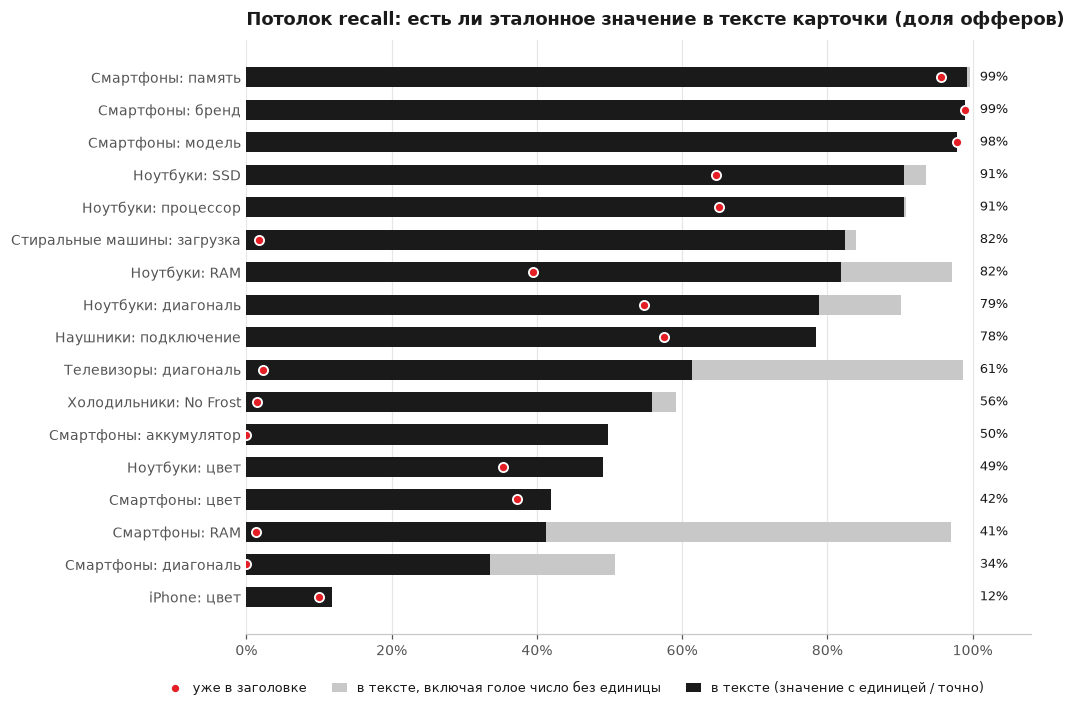

In [12]:
ex = eda.extractability(e)
display(as_pct(ex, ["fill", "в тексте", "в тексте (с голым числом)", "в заголовке"]))
x = e.stats["extractability"]
print(f"все заметные свойства топ-25 категорий (fill ≥ 50%): {x['top25_params_fill_ge_50']}; "
      f"в тексте хотя бы у половины карточек — {x['top25_params_extractable_ge_50']} "
      f"({pct(x['top25_params_extractable_ge_50_share'], 1)}); флаги «Да/Нет» — {pct(x['top25_params_yes_no_flag_share'])}; "
      f"медиана извлекаемости — {pct(x['top25_params_median_extractable'])} (без флагов — {pct(x['top25_params_non_flag_median_extractable'])})")
eda.fig_extractability(e, ex);

**Выводы.**
- Бренд, модель и память смартфона есть в тексте у 98–99% карточек; процессор и SSD ноутбука — у 91%. Это «ядро», которое
  закрывают правила и словари.
- Остальное в тексте есть далеко не всегда: RAM смартфона — 41% (и 97%, если засчитать голое «8» из «8/256»),
  ёмкость аккумулятора — 50%, диагональ смартфона — 34%, цвет iPhone — 12%
  (в тексте английские маркетинговые названия).
- Шире — ещё жёстче: из 1 575 заметных свойств топ-25 категорий (заполнены у ≥ 50% офферов) лишь 109
  (6,9%) встречаются в тексте хотя бы у половины карточек; медиана — 1%. 43% из них —
  флаги «Да/Нет», остальное — габариты, страна, режимы. Извлекать имеет смысл ключевые свойства, а не «все 160 полей».
- Следствия для оценки и продукта: recall считаем и относительно всего эталона, и относительно «извлекаемого»; значение,
  которого нет в тексте, не заполняем автоматически (статус «на проверку» / «нет данных»), иначе это галлюцинация.
  Ценность LLM — в нормализации («Cosmic Orange» → «оранжевый», «8/256» → RAM и память), а не в «угадывании».

## 7. Поисковый спрос: что покупатели называют в запросе

31 млн кликов из поиска агрегированы по парам (категория кликнутого SKU, нормализованный запрос). Детектор
упоминаний (`attrx.data.traffic.Detector`) для каждой категории строит словарь из её каталога — бренды (с кириллическими
написаниями, найденными в логах: «самсунг» → Samsung), токены моделей, частые значения параметров с единицами,
текстовые значения, имена свойств-флагов, цвета — и размечает каждый запрос. Вес атрибута = доля кликов категории,
в запросах которых он назван (`config/traffic_weights.yaml`, сводка — `submission/traffic.json`).

,слов в запросе (6 = 6+),кликов,доля
0,1,7489168.0,"24,2%"
1,2,11056272.0,"35,7%"
2,3,6417110.0,"20,7%"
3,4,3407324.0,"11,0%"
4,5,1544708.0,"5,0%"
5,6,1076765.0,"3,5%"


размечено 255 категорий (93,2% кликов), 1 331 591 пар (категория, запрос)
запрос называет атрибут: 56,5% кликов; характеристику кроме бренда и модели: 24,9%; по типам: brand 32,0%, model 20,2%, number 10,0%, color 1,1%, text 15,7%


,категория,клики,любой атрибут,бренд,модель,характеристика,число с единицей / значение,цвет,текстовое значение
0,Смартфоны (+ iPhone),3670018,"86,7%","54,3%","66,9%","14,3%","10,9%","1,4%","4,1%"
1,Ноутбуки,941126,"66,5%","40,1%","34,4%","24,3%","7,4%","2,1%","18,6%"
2,Телевизоры,1254902,"74,5%","43,0%","13,3%","52,6%","50,0%","1,0%","4,7%"
3,Стиральные машины,1602480,"48,9%","28,5%","6,3%","26,8%","5,3%","0,6%","22,2%"
4,Холодильники,1592842,"46,6%","24,4%","4,9%","27,3%","21,7%","2,0%","6,7%"
5,Наушники,912647,"90,6%","49,7%","35,3%","43,7%","1,0%","1,2%","42,2%"


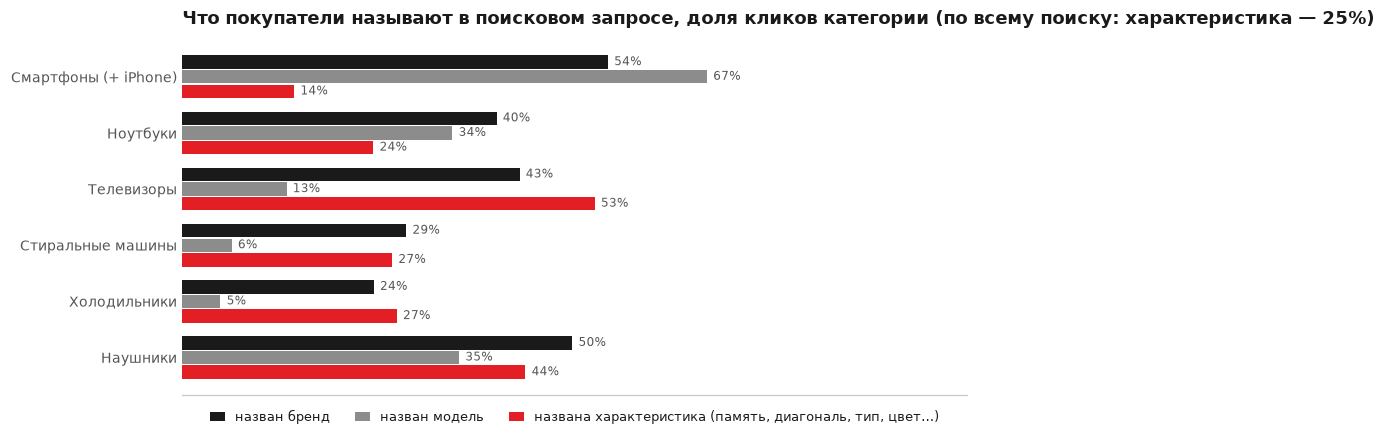

In [13]:
st = eda.search(e)
display(as_pct(st["query_words"].rename(columns={"words": "слов в запросе (6 = 6+)", "clicks": "кликов", "share": "доля"}),
               ["доля"]))
meta = e.traffic()["_meta"]
print(f"размечено {meta['n_categories']} категорий ({pct(meta['clicks_covered_share'], 1)} кликов), "
      f"{num(meta['n_queries'])} пар (категория, запрос)")
print(f"запрос называет атрибут: {pct(meta['any_attribute_share'], 1)} кликов; характеристику кроме бренда и модели: "
      f"{pct(meta['any_param_share'], 1)}; по типам: " + ", ".join(f"{k} {pct(v, 1)}" for k, v in meta["kinds_share"].items()))
display(as_pct(st["kinds"], ["любой атрибут", "бренд", "модель", "характеристика", "число с единицей / значение", "цвет",
                             "текстовое значение"]))
eda.fig_search_kinds(e, st["kinds"]);

Смартфоны


,атрибут,доля кликов,близнецы,примеры
0,vendor,"78,4%",,смартфоны samsung (68 209); смартфоны xiaomi (42 919)
1,model,"60,7%","Серия, Модель",samsung s26 ultra (41 363); samsung s25 ultra (37 874)
2,Встроенная память,"7,2%",Встроенная память (ROM),samsung s26 512gb ultra (2 875); samsung s25 512gb ultra (2 231)
3,Оперативная и встроенная память,"3,5%",,смартфон samsung galaxy a56 5g 8 256 гб (902); honor 400 pro 12 512 (721)
4,Оперативная память,"1,8%",Оперативная память (RAM),honor 400 pro 12 512 (721); poco x8 pro 12 512 (569)
5,Поддержка 5G,"1,7%",,tecno camon 40 pro 5g (2 043); redmi note 15 pro 5g (1 184)
6,Цвет,"1,3%",Цвет производителя,смартфон samsung galaxy a26 5g 8 256gb черный (133); смартфон huawei pura 80 12/256gb ...
7,Состояние,"1,0%",,восстановленный смартфон (7 021); восстановленный (3 243)


Ноутбуки


,атрибут,доля кликов,близнецы,примеры
0,vendor,"40,1%",,ноутбуки huawei (22 270); ноутбуки asus (19 482)
1,model,"34,4%","Серия, Модель",macbook (22 251); макбук (14 455)
2,Игровой,"15,5%",,игровые ноутбуки (88 326); игровой ноутбук (11 544)
3,Диагональ экрана,"5,1%",,16 ноутбук huawei (1 936); ноутбуки huawei 14 (1 605)
4,Объём SSD,"2,6%",,"apple mac ноутбук neo 512 (225); ноутбук asus m1502naq-bq264 15.6""/ryzen 5 150/16гб/51..."
5,Оперативная память,"2,6%",Оперативная память (RAM),"ноутбук asus m1502naq-bq264 15.6""/ryzen 5 150/16гб/512гб/noos/синий(90nb1841-m00lt0) (..."
6,Модель процессора,"2,3%",,thunderobot 911s core d (355); ноутбук intel core i7 (307)
7,Цвет,"2,1%",,"ноутбук asus m1502naq-bq264 15.6""/ryzen 5 150/16гб/512гб/noos/синий(90nb1841-m00lt0) (..."


Телевизоры


,атрибут,доля кликов,близнецы,примеры
0,Диагональ,"49,5%",,телевизоры 55 (61 882); телевизоры 43 (56 752)
1,vendor,"43,0%",,телевизоры samsung (11 688); телевизоры tcl (9 833)
2,model,"13,3%",,телевизоры haier 55 (3 515); телевизоры haier 43 (3 497)
3,Серия,"4,9%",,телевизоры haier 50 (2 493); телевизор tcl 55c6k (2 252)
4,Голосовые помощники,"2,8%",Алиса,телевизор с яндекс алисой (6 824); телевизор яндекс тв станция с алисой (3 943)
5,Цвет,"1,0%",,телевизор белый (655); телевизор 32 белый (220)
6,Диагональ экрана,"0,7%",,телевизор 65 диагональ (114); телевизор 81 см (114)
7,Операционная система,"0,6%",,телевизор сбер салют 43 (284); телевизор сбер салют 55 (226)


Наушники


,атрибут,доля кликов,близнецы,примеры
0,vendor,"49,7%",,наушники apple (35 331); беспроводные наушники jbl (27 239)
1,Тип подключения,"39,5%",,наушники беспроводные (150 018); беспроводные наушники jbl (27 239)
2,model,"35,3%","Серия, Модель",airpods (30 431); airpods 4 (17 907)
3,Тип наушников,"4,1%",,наушники беспроводные накладные (9 910); наушники накладные (3 252)
4,Тип кабеля в комплекте 1,"1,3%",,наушники проводные type c (2 840); наушники apple проводные type c (1 335)
5,Цвет,"1,2%",,наушники tws samsung galaxy buds 4 pro черный 2026 (85); наушники беспроводные белые (75)
6,Встроенный микрофон,"0,8%",,наушники гарнитура с микрофоном проводные (1 386); наушники с микрофоном проводные (828)
7,Подключение по Bluetooth,"0,5%",Поддержка Bluetooth,наушники bluetooth (367); блютуз наушники (307)


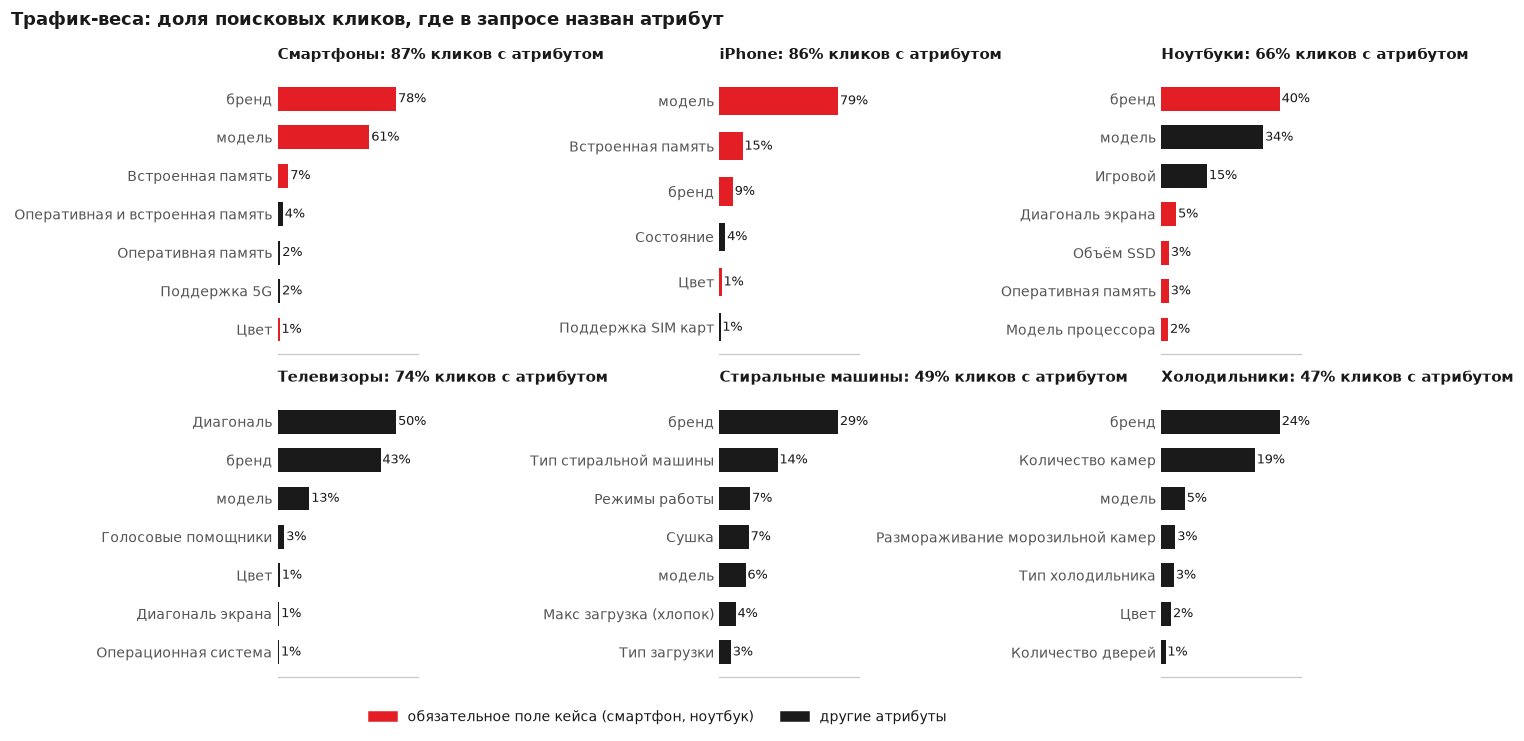

In [14]:
for cid, title in (("761", "Смартфоны"), ("987", "Ноутбуки"), ("1682", "Телевизоры"), ("31607", "Наушники")):
    print(title)
    display(as_pct(st[f"top_{cid}"].head(8), ["доля кликов"]))
eda.fig_traffic_top(e);

**Выводы.**
- Запросы короткие: одно слово — 24% кликов, два — 36%, три — 21%. Но в **56,5%** кликов запрос называет атрибут:
  бренд — 32,0%, модель — 20,2%, характеристику — 24,9% (число с единицей или частое значение —
  10,0%, текстовое значение или свойство-флаг — 15,7%, цвет — 1,1%). Это оценка снизу: «маленький холодильник»
  без значения не считается.
- Спрос на атрибуты сильно зависит от категории: телевизоры ищут по диагонали (50% кликов, «телевизоры 55»), наушники — по
  типу подключения (39%, «беспроводные»), стиральные машины — по типу («узкая», «с вертикальной загрузкой» — 14%)
  и сушке (7%), ноутбуки — по «игровой» (15%), смартфоны — по модели (67%) и бренду (54%),
  из характеристик — по памяти (10%).
- Обязательные поля кейса и реальный спрос совпадают не полностью: у смартфонов диагональ (0,21%) и ёмкость
  аккумулятора (0,05%) почти не ищут, а «Состояние» (восстановленный, 1,0%) — ищут. Поэтому веса для traffic-weighted метрик и очереди
  модерации берём из данных, а не задаём руками: `config/traffic_weights.yaml`.

## 8. Справедливость: карточки М.Видео и партнёров маркетплейса

Только карточки с эталоном. «Значение есть в тексте» — проверка на детерминированной выборке до 300 карточек на
категорию и сегмент в 7 главных категориях (бренд, модель и ключевые свойства каждой категории).

segment,М.Видео,маркетплейс
описание короче 200 символов,"3,0%","1,0%"
есть блок «Характеристики»,"2,1%","8,0%"
в фиде ≥ 20 характеристик,"42,4%","49,2%"
заполнены все ключевые свойства (6 главных категорий),"94,8%","82,3%"
бренд есть в тексте,"99,6%","99,9%"
модель есть в тексте,"98,0%","98,1%"
значение ключевого свойства есть в тексте,"47,3%","51,7%"


медиана длины описания: {'М.Видео': 868.0, 'маркетплейс': 1057.0} | медиана характеристик в фиде: {'М.Видео': 17.0, 'маркетплейс': 19.0} | проверок извлекаемости: 24847


segment,category_id,М.Видео,маркетплейс
0,Телевизоры,"96,3%","74,3%"
1,Стиральные машины,"96,5%","95,7%"
2,Наушники,"93,3%","80,6%"
3,Холодильники,"95,9%","90,0%"
4,Смартфоны,"96,9%","87,6%"
5,iPhone,"1,5%","8,0%"
6,Ноутбуки,"87,6%","68,8%"


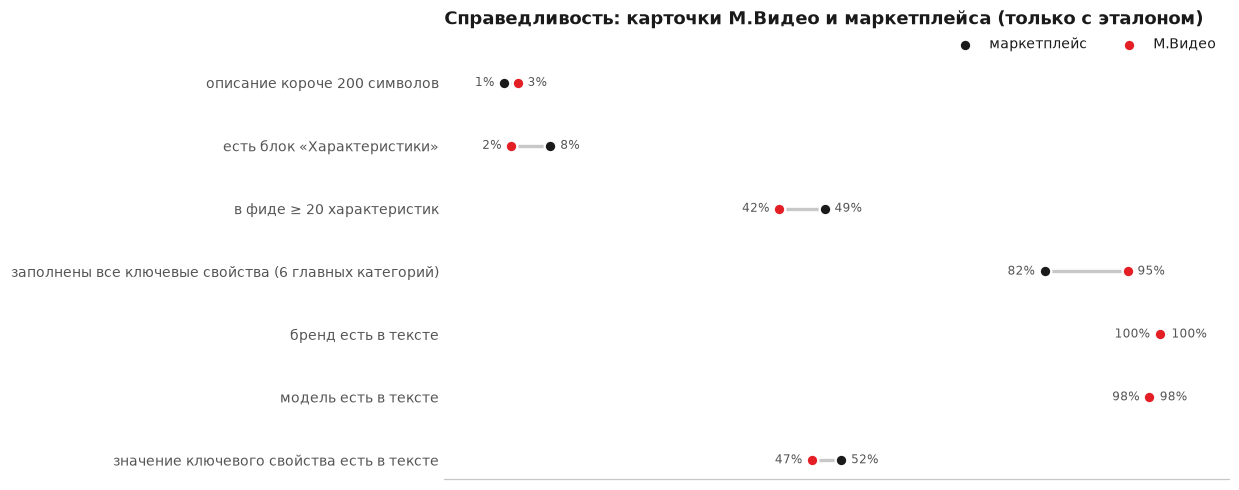

In [15]:
fa = eda.fairness(e)
display(fa.map(lambda v: pct(v, 1)))
fs = e.stats["fairness"]
print("медиана длины описания:", fs["desc_median"], "| медиана характеристик в фиде:", fs["params_median"],
      "| проверок извлекаемости:", fs["extract_checks"])
kp = eda.key_presence(e)
display(as_pct(kp.groupby(["category_id", "segment"]).all_key.mean().unstack().rename(index=eda.MAIN).reset_index(),
               ["М.Видео", "маркетплейс"]))
eda.fig_fairness(e, fa);

**Выводы.**
- Тексты партнёров маркетплейса не беднее: описание короче 200 символов у 1% против 3% у
  М.Видео, значение ключевого свойства есть в тексте у 52% против 47%, блок
  «Характеристики» — у 8% против 2%.
- А вот в каталоге у офферов маркетплейса все ключевые свойства заполнены реже: 82% против 95% (6 главных категорий,
  без iPhone, где ёмкость аккумулятора пуста у всех). Особенно телевизоры и ноутбуки.
- Значит, извлечение из текста в первую очередь выравнивает карточки партнёров. Метрики и покрытие отчитываем по
  сегментам продавца (`submission/segments.json`), пороги автопринятия — одинаковые, без «скидок» маркетплейсу.

## 9. Что это значит для бизнеса (цифры для питча)

Формулировки — ровно то, что показывают данные: «без структурированных атрибутов» = SKU нет в выданном YML-снимке
каталога. Это не значит, что у товара нет атрибутов в системах М.Видео, — только что в данных кейса их нет.

In [16]:
biz = eda.business(e)
eda.write_json(e.processed / "eda_stats.json", e.stats)
eda.write_json(e.processed / "business_stats.json", biz)
c, sch = biz["catalog"], biz["search"]
print(f"карточек без структурированных атрибутов в данных: {num(c['cards_without_structured_attributes'])} "
      f"({pct(c['cards_without_structured_attributes_share'], 1)}), без категории: {num(c['cards_without_category'])}")
print(f"клики с атрибутом в запросе: {pct(sch['clicks_with_any_attribute_in_query_share'], 1)}; "
      f"с характеристикой кроме бренда/модели: {pct(sch['clicks_with_characteristic_beyond_brand_model_share'], 1)}")
gaps = pd.DataFrame(biz["required_attributes_gaps"]).T[["title", "offers", "offers_missing_any_key_param",
                                                        "search_clicks_on_offers_missing_key_param", "key_params"]]
display(as_pct(gaps, ["offers_missing_any_key_param", "search_clicks_on_offers_missing_key_param"]).rename(columns={
    "title": "категория", "offers": "офферов", "offers_missing_any_key_param": "офферов без ≥1 ключевого свойства",
    "search_clicks_on_offers_missing_key_param": "кликов поиска на такие офферы", "key_params": "ключевые свойства"}))

карточек без структурированных атрибутов в данных: 935 845 (79,5%), без категории: 880 632
клики с атрибутом в запросе: 56,5%; с характеристикой кроме бренда/модели: 24,9%


,категория,офферов,офферов без ≥1 ключевого свойства,кликов поиска на такие офферы,ключевые свойства
1682,Телевизоры,3175,"19,8%","8,3%","[Диагональ, Разрешение, Технология экрана, Цвет]"
2447,Стиральные машины,1723,"4,1%","4,4%","[Тип стиральной машины, Максимальная загрузка, Ширина, Цвет]"
31607,Наушники,2881,"14,8%","9,0%","[Тип подключения, Тип наушников, Цвет]"
666,Холодильники,2438,"8,1%","8,6%","[Тип холодильника, Размораживание морозильной камеры, Высота, Цвет]"
761,Смартфоны,7988,"9,5%","5,5%","[Встроенная память (ROM), Диагональ, Емкость аккумулятора, Цвет, Оперативная память (R..."
914,iPhone,4320,"93,0%","90,8%","[Встроенная память (ROM), Диагональ, Емкость аккумулятора, Цвет]"
987,Ноутбуки,3580,"26,2%","9,6%","[Модель процессора, Оперативная память (RAM), Объём SSD, Диагональ экрана, Цвет]"


- **79,5% карточек выгрузки (935 845) не имеют структурированных атрибутов в данных** —
  для них характеристики можно получить только из текста; у 880 632 нет даже категории.
- **57% поисковых кликов** приходятся на запросы, где покупатель назвал атрибут, **25%** — характеристику
  кроме бренда и модели. Каждое незаполненное свойство — это карточка, которая не попадает в фильтр и выдачу по такому запросу.
- Даже в курируемом каталоге у 4–26% офферов главных категорий не заполнено хотя бы одно ключевое свойство
  (ноутбуки — 26%, телевизоры — 20%, наушники — 15%); на такие офферы приходится
  4–10% поисковых кликов категории. У iPhone — 93% (нет ёмкости аккумулятора).
- Разрыв по сегментам: полностью описано 95% офферов М.Видео и 82% офферов партнёров — автозаполнение из текста
  в первую очередь помогает маркетплейсу.

## 10. Что это значит для пайплайна

1. **Вход = очищенный текст.** HTML в эталонных 72–81% описаний → `clean_html`; блок «Характеристики» (у 31% карточек) → `seller_attrs` —
   первый и самый дешёвый источник с алиасами ключей на таксономию.
2. **Сначала категория.** У 74,8% карточек категории нет → классификатор по тексту перед извлечением; `seo_id` кликов —
   дополнительный сигнал (совпадает с каталогом у 97,7%).
3. **Таксономия из данных, а не руками.** 10 696 свойств и 3 595 категорий с медианой 10 офферов: обязательные
   атрибуты = заполненность в каталоге × спрос в поиске (`taxonomy_candidates.json`, `config/traffic_weights.yaml`), для хвоста —
   универсальные атрибуты + LLM (cold start).
4. **Нормализация до канона.** 12 написаний ГБ, пары «8/256» и «12+256», дюймы/см/мм, английские и маркетинговые цвета →
   единицы и справочники допустимых значений; бакеты фильтров выводятся из точного значения.
5. **Честная оценка.** Эталон — точное `_search`-значение оффера; recall — относительно всего и «извлекаемого» эталона
   (потолок: диагональ смартфона в тексте у 34%); holdout 24 143 карточек; разрезы head/torso/tail и М.Видео/маркетплейс.
6. **Не выдумывать.** Значение, которого нет в тексте, не принимается автоматически: заземление цитатой (`evidence_span`),
   иначе статус «на проверку» / «нет данных».
7. **Приоритеты по деньгам.** Traffic-weighted F1 и очередь модерации — по весам спроса: телевизор — диагональ (50% кликов),
   наушники — тип подключения (39%), смартфон — модель, бренд, память.